# Model Training & Evaluation: recession-focused version



In [1]:
!pip install -q transformers torch gensim scikit-learn statsmodels pandas tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 54.3 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
from datetime import datetime

# ---- CONFIG ----
DATA_DIR = "/content/drive/MyDrive/brexit_covid_datasets"
ECON_INDICATOR_PATH = f"{DATA_DIR}/economic_indicator.csv"

OUTLETS = ["bbc", "dailymail", "guardian"]
TOPICS = ["brexit", "covid"]

AGG_FREQ = "MS"
LSTM_LOOKBACK = 3
TEST_FRACTION = 0.2
RANDOM_STATE = 42

# the recession windows this thesis is actually about — UK's two confirmed recessions
# that fall inside the dataset's date range:
#   1) the official COVID recession (Q1-Q2 2020)
#   2) the 2023 H2 "technical recession" confirmed by ONS in Feb 2024
#      (Q3 2023 GDP -0.1%, Q4 2023 GDP -0.3%)
# Testing both — instead of just 2020 — gives two independent events rather than
# one, which matters a lot given how small this sample already is.
RECESSION_WINDOWS = [
    {"name": "2020 COVID recession", "start": pd.Timestamp("2020-01-01"), "end": pd.Timestamp("2020-06-30")},
    {"name": "2023 H2 recession",    "start": pd.Timestamp("2023-07-01"), "end": pd.Timestamp("2023-12-31")},
]

LEADUP_MONTHS = 6            # window tested right BEFORE each recession starts
CALM_COMPARISON_MONTHS = 6   # window tested right AFTER each recession ends


In [3]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass

Mounted at /content/drive


## Load data: articles per (outlet, topic), and the economic indicator

In [4]:
def load_outlet_topic(outlet, topic):
    df = pd.read_csv(f"{DATA_DIR}/{outlet}_brexit_covid_text_FINAL.csv")
    df = df[df["topic"] == topic].copy()
    df["publish_date"] = pd.to_datetime(df["publish_date"], errors="coerce", utc=True).dt.tz_localize(None)
    df = df.dropna(subset=["publish_date", "text"]).sort_values("publish_date").reset_index(drop=True)
    return df

datasets = {}
for outlet in OUTLETS:
    for topic in TOPICS:
        key = (outlet, topic)
        try:
            df = load_outlet_topic(outlet, topic)
            datasets[key] = df
            print(f"{outlet}/{topic}: {len(df)} articles, {df['publish_date'].min()} to {df['publish_date'].max()}")
        except FileNotFoundError:
            print(f"{outlet}/{topic}: FILE NOT FOUND")

bbc/brexit: 794 articles, 2012-06-17 00:00:00 to 2026-07-21 00:00:00
bbc/covid: 790 articles, 2020-01-10 00:00:00 to 2026-08-08 00:00:00
dailymail/brexit: 799 articles, 2012-01-28 00:00:00 to 2026-03-16 00:00:00
dailymail/covid: 798 articles, 2020-01-05 00:00:00 to 2026-03-16 00:00:00
guardian/brexit: 800 articles, 2012-02-10 21:00:04 to 2026-08-04 04:00:12
guardian/covid: 800 articles, 2020-03-23 20:41:20 to 2026-08-08 20:03:34


In [5]:
econ = pd.read_csv(ECON_INDICATOR_PATH)
econ["date"] = pd.to_datetime(econ["date"])
econ = econ.set_index("date").resample(AGG_FREQ).mean().rename(columns={"value": "econ_value"})
print(econ.head())
print(f"Economic indicator range: {econ.index.min()} to {econ.index.max()}, {len(econ)} months")

            econ_value
date                  
1997-01-01        61.6
1997-02-01        61.9
1997-03-01        61.8
1997-04-01        62.6
1997-05-01        62.1
Economic indicator range: 1997-01-01 00:00:00 to 2026-05-01 00:00:00, 353 months


## Model 1 — FinBERT sentiment extraction

In [ ]:
from transformers import pipeline

finbert = pipeline(
    "sentiment-analysis",
    model="ProsusAI/finbert",
    tokenizer="ProsusAI/finbert",
    truncation=True,
    max_length=512,
    model_kwargs={"use_safetensors": False},
)

def finbert_signed_scores(texts, batch_size=16):
    scores = []
    for i in range(0, len(texts), batch_size):
        batch = [t[:2000] if isinstance(t, str) else "" for t in texts[i:i+batch_size]]
        results = finbert(batch)
        for r in results:
            label, score = r["label"].lower(), r["score"]
            scores.append(score if label == "positive" else (-score if label == "negative" else 0.0))
    return scores



import os

FINBERT_CACHE_DIR = f"{DATA_DIR}/finbert_cache"
os.makedirs(FINBERT_CACHE_DIR, exist_ok=True)

def finbert_scores_cached(df, outlet, topic):
    cache_path = f"{FINBERT_CACHE_DIR}/{outlet}_{topic}_finbert_scores.csv"
    # cache hit: same number of rows as the current dataframe -> trust it and
    # skip the (slow) model entirely
    if os.path.exists(cache_path):
        cached = pd.read_csv(cache_path)
        if len(cached) == len(df):
            print(f"  (loaded cached FinBERT scores for {outlet}/{topic} - skipping model)")
            return cached["finbert_score"].tolist()
        else:
            print(f"  (cache for {outlet}/{topic} doesn't match current data length - recomputing)")
    # cache miss (or stale cache): compute normally, then save for next time
    scores = finbert_signed_scores(df["text"].tolist())
    pd.DataFrame({"finbert_score": scores}).to_csv(cache_path, index=False)
    return scores


config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

## Model 2 — LDA topic modeling

In [7]:
from gensim import corpora
from gensim.models import LdaModel
from gensim.utils import simple_preprocess
from gensim.parsing.preprocessing import STOPWORDS

def fit_lda(texts, num_topics=5, passes=10):
    tokenized = [[w for w in simple_preprocess(str(t)) if w not in STOPWORDS and len(w) > 2] for t in texts]
    dictionary = corpora.Dictionary(tokenized)
    dictionary.filter_extremes(no_below=2, no_above=0.5)
    corpus = [dictionary.doc2bow(t) for t in tokenized]
    lda = LdaModel(corpus=corpus, id2word=dictionary, num_topics=num_topics, passes=passes, random_state=RANDOM_STATE)
    return lda, dictionary, corpus

def lda_topic_scores(lda, corpus):
    scores = []
    for bow in corpus:
        dist = dict(lda.get_document_topics(bow, minimum_probability=0))
        scores.append(max(dist.values()) if dist else 0.0)
    return scores

In [8]:
EWMA_SPANS = {"1y": 365, "3m": 90}  # calendar days

def weighted_recency_features(df, score_col, prefix, agg_freq=AGG_FREQ):
    """
    df must have a 'publish_date' column and an article-level `score_col`.
    Returns a DataFrame, indexed at `agg_freq` (monthly, to match the rest of the
    pipeline), with recency-weighted level and momentum features at each span in
    EWMA_SPANS.
    """
    daily = df.set_index("publish_date")[score_col].resample("D").mean()
    # fill days with no articles by carrying the trend forward/backward, rather than
    # leaving gaps that would distort the EWMA's notion of "recent"
    daily = daily.interpolate(limit_direction="both")
    daily_change = daily.diff()

    out = pd.DataFrame(index=daily.index)
    for label, span in EWMA_SPANS.items():
        out[f"{prefix}_ewm_{label}"] = daily.ewm(span=span, adjust=False).mean()
        out[f"{prefix}_ewm_change_{label}"] = daily_change.ewm(span=span, adjust=False).mean()

    # snapshot the running weighted average as of each month (it already encodes the
    # full weighted history up to that point, so "last" rather than "mean" is the
    # right way to collapse daily -> monthly here)
    return out.resample(agg_freq).last()


## Model 3 — FinBERT-LSTM (sequence model)




In [9]:
import torch
import torch.nn as nn

class SentimentLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=16):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :]).squeeze(-1)

# def train_lstm(X_train, y_train, epochs=150, lr=0.01, hidden_size=16, patience=15, val_fraction=0.2):
#     """Trains with early stopping on a validation slice cut from the END of the
#     training period (never shuffled — this is time series, so validation must
#     stay chronologically after the data it's validated against). Stops once
#     validation loss hasn't improved for `patience` epochs and restores the
#     best-seen weights, instead of just running a fixed epoch count blindly."""
#     n = len(y_train)
#     n_val = max(1, int(n * val_fraction)) if n >= 10 else 0

#     if n_val > 0:
#         X_fit, y_fit = X_train[:-n_val], y_train[:-n_val]
#         X_val, y_val = X_train[-n_val:], y_train[-n_val:]
#     else:
#         X_fit, y_fit = X_train, y_train
#         X_val, y_val = None, None

#     model = SentimentLSTM(input_size=1, hidden_size=hidden_size)
#     opt = torch.optim.Adam(model.parameters(), lr=lr)
#     loss_fn = nn.MSELoss()
#     Xt = torch.tensor(X_fit).unsqueeze(-1)
#     yt = torch.tensor(y_fit)

#     best_val_loss = float("inf")
#     best_state = None
#     epochs_without_improve = 0
#     stopped_at = epochs

#     for epoch in range(epochs):
#         model.train()
#         opt.zero_grad()
#         loss = loss_fn(model(Xt), yt)
#         loss.backward()
#         opt.step()

#         if X_val is not None:
#             model.eval()
#             with torch.no_grad():
#                 Xv = torch.tensor(X_val).unsqueeze(-1)
#                 yv = torch.tensor(y_val)
#                 val_loss = loss_fn(model(Xv), yv).item()
#             if val_loss < best_val_loss:
#                 best_val_loss = val_loss
#                 best_state = {k: v.clone() for k, v in model.state_dict().items()}
#                 epochs_without_improve = 0
#             else:
#                 epochs_without_improve += 1
#                 if epochs_without_improve >= patience:
#                     stopped_at = epoch + 1
#                     break

#     if best_state is not None:
#         model.load_state_dict(best_state)

#     model._stopped_at_epoch = stopped_at  # stashed for reporting, not used by the model itself
#     return model



# def predict_lstm(model, X):
#     model.eval()
#     with torch.no_grad():
#         return model(torch.tensor(X).unsqueeze(-1)).numpy()

def train_lstm(X_train, y_train, epochs=150, lr=0.01, hidden_size=16, patience=15, val_fraction=0.2):
    torch.manual_seed(RANDOM_STATE)
    n = len(y_train)
    n_val = max(1, int(n * val_fraction)) if n >= 10 else 0

    if n_val > 0:
        X_fit, y_fit = X_train[:-n_val], y_train[:-n_val]
        X_val, y_val = X_train[-n_val:], y_train[-n_val:]
    else:
        X_fit, y_fit = X_train, y_train
        X_val, y_val = None, None

    model = SentimentLSTM(input_size=1, hidden_size=hidden_size)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    Xt = torch.tensor(X_fit).unsqueeze(-1)
    yt = torch.tensor(y_fit)

    best_val_loss = float("inf")
    best_state = None
    epochs_without_improve = 0
    stopped_at = epochs
    train_loss_history = []   # NEW
    val_loss_history = []     # NEW

    for epoch in range(epochs):
        model.train()
        opt.zero_grad()
        loss = loss_fn(model(Xt), yt)
        loss.backward()
        opt.step()

        # measure train loss the same way as val_loss (eval mode, no grad) so
        # the two numbers are directly comparable, not just "training loss
        # during a gradient step" vs "validation loss in eval mode"
        model.eval()
        with torch.no_grad():
            train_loss_history.append(loss_fn(model(Xt), yt).item())

        if X_val is not None:
            with torch.no_grad():
                Xv = torch.tensor(X_val).unsqueeze(-1)
                yv = torch.tensor(y_val)
                val_loss = loss_fn(model(Xv), yv).item()
            val_loss_history.append(val_loss)
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
                epochs_without_improve = 0
            else:
                epochs_without_improve += 1
                if epochs_without_improve >= patience:
                    stopped_at = epoch + 1
                    break

    if best_state is not None:
        model.load_state_dict(best_state)
        model._stopped_at_epoch = stopped_at
        model._train_loss_history = train_loss_history
        model._val_loss_history = val_loss_history
        model._train_var = float(np.var(y_fit))
        model._val_var = float(np.var(y_val)) if X_val is not None else None
        return model



    model._stopped_at_epoch = stopped_at
    model._train_loss_history = train_loss_history   # NEW
    model._val_loss_history = val_loss_history        # NEW
    return model

def predict_lstm(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X).unsqueeze(-1)).numpy()


## Baselines — naive persistence and ARIMA (news-free)

ARIMA's order is now selected by AIC on the training data only (see `select_arima_order`
below) instead of being fixed at (1,0,0) — a small, standard, leak-free model-selection
step: AIC never looks at the test set, only at how well each candidate order fits the
training period itself.


In [10]:
from statsmodels.tsa.arima.model import ARIMA

def naive_persistence_forecast(y_train, n_test):
    """Predicts every test point as 'no change from the last known value'."""
    return np.full(n_test, y_train[-1])

def select_arima_order(y_train, candidate_orders=((1, 0, 0), (1, 0, 1))):
    """Picks the ARIMA order with the lowest AIC on the training data only.
    This is standard, leak-free model selection — AIC is computed purely from
    how well each order fits the training period, never touching the test set."""
    best_order, best_aic = (1, 0, 0), float("inf")
    for order in candidate_orders:
        try:
            fit = ARIMA(y_train, order=order).fit()
            if fit.aic < best_aic:
                best_aic = fit.aic
                best_order = order
        except Exception:
            continue
    return best_order

def fit_arima_baseline(y_train, n_test, order=None):
    """Classical time-series baseline using only the economic series' own history.
    If no order is given, one is selected via AIC on the training data (see above)."""
    if order is None:
        order = select_arima_order(y_train)
    try:
        model = ARIMA(y_train, order=order).fit()
        return np.asarray(model.forecast(steps=n_test)), order
    except Exception as e:
        print(f"ARIMA failed ({e}) — falling back to naive baseline")
        return naive_persistence_forecast(y_train, n_test), order


## Main loop — all models + baselines, all six (outlet, topic) datasets, predicting GDP GROWTH (not level)



In [11]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

RIDGE_ALPHA_GRID = (0.1, 0.3, 1.0, 3.0, 10.0, 30.0)

def tune_ridge_alpha(X_train, y_train, alphas=RIDGE_ALPHA_GRID, min_months_for_cv=24):
    """Time-series-aware hyperparameter search for Ridge's alpha.
    Uses expanding-window cross-validation (TimeSeriesSplit): every validation fold
    is strictly LATER in time than the fold it's trained on, so no future data ever
    leaks into a training fold — the key difference from ordinary k-fold CV, which
    would shuffle months randomly and leak information backward in time.
    Falls back to the scikit-learn default (alpha=1.0) if there's too little
    training data to split into folds reliably."""
    n = len(y_train)
    if n < min_months_for_cv:
        return 1.0, {1.0: None}

    n_splits = min(5, max(2, n // 12))
    tscv = TimeSeriesSplit(n_splits=n_splits)

    scores = {}
    for alpha in alphas:
        fold_rmses = []
        for tr_idx, val_idx in tscv.split(X_train):
            if len(tr_idx) < 3 or len(val_idx) < 1:
                continue
            m = Ridge(alpha=alpha).fit(X_train[tr_idx], y_train[tr_idx])
            pred = m.predict(X_train[val_idx])
            fold_rmses.append(mean_squared_error(y_train[val_idx], pred) ** 0.5)
        scores[alpha] = np.mean(fold_rmses) if fold_rmses else np.inf

    best_alpha = min(scores, key=scores.get)
    return best_alpha, scores

def evaluate(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    # directional accuracy: did the model get the SIGN of growth right (up vs down),
    # regardless of the exact magnitude? This is the closest equivalent to an
    # "accuracy" score for a regression target, and it's the number that most directly
    # answers "does news language predict which way the economy is moving."
    direction_match = np.sign(y_true) == np.sign(y_pred)
    return {
        "rmse": mean_squared_error(y_true, y_pred) ** 0.5,
        "mae": mean_absolute_error(y_true, y_pred),
        "r2": r2_score(y_true, y_pred) if len(y_true) > 1 else float("nan"),
        "directional_accuracy": direction_match.mean(),
    }

results = []

for (outlet, topic), df in datasets.items():
    print(f"\n=== {outlet} / {topic} ({len(df)} articles) ===")
    if len(df) < 20:
        print("Too few articles to model meaningfully — skipping.")
        continue

    df["finbert_score"] = finbert_scores_cached(df, outlet, topic)  # FIX: cached now, so an interrupted run can resume without redoing finished (outlet, topic) pairs
    monthly_sent = df.set_index("publish_date")["finbert_score"].resample(AGG_FREQ).mean()

    lda, dictionary, corpus = fit_lda(df["text"].tolist())
    df["lda_score"] = lda_topic_scores(lda, corpus)
    monthly_lda = df.set_index("publish_date")["lda_score"].resample(AGG_FREQ).mean()

    weighted_feats = weighted_recency_features(df, "finbert_score", "finbert")
    lda_weighted_feats = weighted_recency_features(df, "lda_score", "lda")
    merged = pd.DataFrame({"finbert": monthly_sent, "lda": monthly_lda}) \
    .join(weighted_feats, how="left") \
    .join(lda_weighted_feats, how="left") \
    .join(econ, how="inner")
    merged = merged.ffill().dropna()
    merged["growth"] = merged["econ_value"].pct_change() * 100   # <-- target is now growth, not level
    merged = merged.dropna()
    n_months = len(merged)
    print(f"Merged monthly series: {n_months} months")
    if n_months < 12:
        print("Fewer than 12 months of overlapping data — skipping.")
        continue

    split_idx = int(n_months * (1 - TEST_FRACTION))
    y = merged["growth"].values

    # ---- Model 1: FinBERT + Ridge (alpha tuned via time-series CV) ----
    X1 = merged[["finbert"]].values
    alpha1, _ = tune_ridge_alpha(X1[:split_idx], y[:split_idx])
    m1 = Ridge(alpha=alpha1).fit(X1[:split_idx], y[:split_idx])
    pred1 = m1.predict(X1[split_idx:])
    results.append({"outlet": outlet, "topic": topic, "model": "FinBERT+Ridge", **evaluate(y[split_idx:], pred1), "n_months": n_months, "tuned_param": f"alpha={alpha1}"})

    # ---- Model 2: LDA + Ridge (alpha tuned via time-series CV) ----
    X2 = merged[["lda"]].values
    alpha2, _ = tune_ridge_alpha(X2[:split_idx], y[:split_idx])
    m2 = Ridge(alpha=alpha2).fit(X2[:split_idx], y[:split_idx])
    pred2 = m2.predict(X2[split_idx:])
    results.append({"outlet": outlet, "topic": topic, "model": "LDA+Ridge", **evaluate(y[split_idx:], pred2), "n_months": n_months, "tuned_param": f"alpha={alpha2}"})

    # ---- Model 2.5: FinBERT + LDA combined + Ridge (alpha tuned via time-series CV) ----
    X_combined = merged[["finbert", "lda"]].values
    alpha_c, _ = tune_ridge_alpha(X_combined[:split_idx], y[:split_idx])
    m_combined = Ridge(alpha=alpha_c).fit(X_combined[:split_idx], y[:split_idx])
    pred_combined = m_combined.predict(X_combined[split_idx:])
    results.append({"outlet": outlet, "topic": topic, "model": "FinBERT+LDA+Ridge", **evaluate(y[split_idx:], pred_combined), "n_months": n_months, "tuned_param": f"alpha={alpha_c}"})

    # ---- Model 2.75: FinBERT + recency-weighted (EWMA) features + Ridge ----
    weighted_cols = [c for c in merged.columns if c.startswith("finbert_ewm")]
    X_weighted = merged[["finbert"] + weighted_cols].values
    alpha_w, _ = tune_ridge_alpha(X_weighted[:split_idx], y[:split_idx])
    m_weighted = Ridge(alpha=alpha_w).fit(X_weighted[:split_idx], y[:split_idx])
    pred_weighted = m_weighted.predict(X_weighted[split_idx:])
    results.append({"outlet": outlet, "topic": topic, "model": "FinBERT+WeightedMA+Ridge", **evaluate(y[split_idx:], pred_weighted), "n_months": n_months, "tuned_param": f"alpha={alpha_w}"})

    # ---- Model 2.85: LDA + recency-weighted (EWMA) features + Ridge ----
    lda_weighted_cols = [c for c in merged.columns if c.startswith("lda_ewm")]
    X_lda_weighted = merged[["lda"] + lda_weighted_cols].values
    alpha_lw, _ = tune_ridge_alpha(X_lda_weighted[:split_idx], y[:split_idx])
    m_lda_weighted = Ridge(alpha=alpha_lw).fit(X_lda_weighted[:split_idx], y[:split_idx])
    pred_lda_weighted = m_lda_weighted.predict(X_lda_weighted[split_idx:])
    results.append({"outlet": outlet, "topic": topic, "model": "LDA+WeightedMA+Ridge", **evaluate(y[split_idx:], pred_lda_weighted), "n_months": n_months, "tuned_param": f"alpha={alpha_lw}"})
    # ---- Model 3: FinBERT-LSTM (early stopping — see train_lstm) ----
    series = merged["finbert"].values.astype(np.float32)
    growth_series = merged["growth"].values.astype(np.float32)
    if n_months - LSTM_LOOKBACK < 12:
        print("Not enough months for LSTM lookback — skipping Model 3.")
    else:
        Xs, ys = [], []
        for i in range(len(series) - LSTM_LOOKBACK):
            Xs.append(series[i:i + LSTM_LOOKBACK])
            ys.append(growth_series[i + LSTM_LOOKBACK])
        Xs, ys = np.array(Xs), np.array(ys)
        split_seq = int(len(Xs) * (1 - TEST_FRACTION))

        y_scaler = StandardScaler()
        y_train_scaled = y_scaler.fit_transform(ys[:split_seq].reshape(-1, 1)).flatten()
        # lstm_model = train_lstm(Xs[:split_seq], y_train_scaled)

        lstm_model = train_lstm(Xs[:split_seq], y_train_scaled)
        # print(f"{outlet}/{topic} LSTM — train_loss={lstm_model._train_loss_history[-1]:.4f}, "
        #       f"best_val_loss={lstm_model._val_loss_history[lstm_model._stopped_at_epoch-1]:.4f}")
        train_r2 = 1 - lstm_model._train_loss_history[-1] / lstm_model._train_var
        val_r2 = 1 - lstm_model._val_loss_history[-1] / lstm_model._val_var
        print(f"{outlet}/{topic} LSTM — train_R2={train_r2:.3f}, val_R2={val_r2:.3f}")
        pred3_scaled = predict_lstm(lstm_model, Xs[split_seq:])
        pred3_scaled = predict_lstm(lstm_model, Xs[split_seq:])
        pred3 = y_scaler.inverse_transform(pred3_scaled.reshape(-1, 1)).flatten()

        results.append({"outlet": outlet, "topic": topic, "model": "FinBERT-LSTM", **evaluate(ys[split_seq:], pred3), "n_months": len(Xs), "tuned_param": f"stopped_epoch={lstm_model._stopped_at_epoch}"})

    # ---- Baselines: naive persistence + ARIMA (no news data used) ----
    naive_pred = naive_persistence_forecast(y[:split_idx], len(y) - split_idx)
    results.append({"outlet": outlet, "topic": topic, "model": "Naive (no-change)", **evaluate(y[split_idx:], naive_pred), "n_months": n_months, "tuned_param": ""})

    arima_pred, arima_order = fit_arima_baseline(y[:split_idx], len(y) - split_idx)
    results.append({"outlet": outlet, "topic": topic, "model": "ARIMA(auto)", **evaluate(y[split_idx:], arima_pred), "n_months": n_months, "tuned_param": f"order={arima_order}"})

results_df = pd.DataFrame(results)
print("\n\n=== FINAL RESULTS (predicting GDP growth, with baselines) ===")
print(results_df)
results_df.to_csv(f"{DATA_DIR}/model_results_growth.csv", index=False)
print(f"\nSaved to {DATA_DIR}/model_results_growth.csv")



=== bbc / brexit (794 articles) ===


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Merged monthly series: 167 months
bbc/brexit LSTM — train_R2=0.006, val_R2=-0.143

=== bbc / covid (790 articles) ===
Merged monthly series: 76 months
bbc/covid LSTM — train_R2=0.002, val_R2=-10.114

=== dailymail / brexit (799 articles) ===
Merged monthly series: 170 months
dailymail/brexit LSTM — train_R2=0.002, val_R2=-0.053

=== dailymail / covid (798 articles) ===
Merged monthly series: 74 months
dailymail/covid LSTM — train_R2=0.170, val_R2=-2.183

=== guardian / brexit (800 articles) ===
Merged monthly series: 171 months
guardian/brexit LSTM — train_R2=0.001, val_R2=-0.011

=== guardian / covid (800 articles) ===
Merged monthly series: 74 months
guardian/covid LSTM — train_R2=0.079, val_R2=-3.406


=== FINAL RESULTS (predicting GDP growth, with baselines) ===
       outlet   topic                     model      rmse       mae  \
0         bbc  brexit             FinBERT+Ridge  0.242694  0.205655   
1         bbc  brexit                 LDA+Ridge  0.242987  0.206718   
2         

overfitting diagnostics were run specifically for the LSTM, given its larger parameter count and lack of built -
in regularization; the Ridge models' regularization was tuned via time-series cross-validation, which addresses the same risk by construction

## Recession-specific test (Brexit datasets only)


In [12]:
recession_results = []

for outlet in OUTLETS:
    key = (outlet, "brexit")
    if key not in datasets:
        continue
    df = datasets[key]
    if "finbert_score" not in df.columns:
        print(f"{outlet}/brexit: run the main loop cell first — finbert_score not found.")
        continue

    monthly_sent = df.set_index("publish_date")["finbert_score"].resample(AGG_FREQ).mean()
    merged = pd.DataFrame({"finbert": monthly_sent}).join(econ, how="inner")
    merged = merged.ffill().dropna()
    merged["growth"] = merged["econ_value"].pct_change() * 100
    merged = merged.dropna()

    for window in RECESSION_WINDOWS:
        rec_start, rec_end, label = window["start"], window["end"], window["name"]

        train = merged[merged.index < rec_start]
        leadup_start = rec_start - pd.DateOffset(months=LEADUP_MONTHS)
        test_leadup = merged[(merged.index >= leadup_start) & (merged.index < rec_start)]
        test_recession = merged[(merged.index >= rec_start) & (merged.index <= rec_end)]
        calm_end = rec_end + pd.DateOffset(months=CALM_COMPARISON_MONTHS)
        test_calm = merged[(merged.index > rec_end) & (merged.index <= calm_end)]

        print(f"{outlet}/brexit [{label}]: {len(train)} training months, "
              f"{len(test_leadup)} lead-up months, {len(test_recession)} recession months, "
              f"{len(test_calm)} calm-comparison months")

        if len(train) < 24 or len(test_recession) < 2:
            print(f"  -> not enough data for {label}, skipping {outlet}/brexit")
            continue

        alpha_r, _ = tune_ridge_alpha(train[["finbert"]].values, train["growth"].values)
        print(f"  tuned alpha for {outlet}/{label}: {alpha_r}")
        m = Ridge(alpha=alpha_r).fit(train[["finbert"]].values, train["growth"].values)

        for period_name, test_set in [
            ("lead-up (pre-recession)", test_leadup),
            ("recession", test_recession),
            ("calm (post-recession)", test_calm),
        ]:
            if len(test_set) < 2:
                continue
            pred = m.predict(test_set[["finbert"]].values)
            recession_results.append({
                "outlet": outlet,
                "recession": label,
                "period": period_name,
                **evaluate(test_set["growth"].values, pred),
                "n_months": len(test_set),
                "tuned_param": f"alpha={alpha_r}",
            })

recession_df = pd.DataFrame(recession_results)
print("\n\n=== LEAD-UP vs RECESSION vs CALM COMPARISON (Brexit datasets, FinBERT+Ridge) ===")
print(recession_df)
recession_df.to_csv(f"{DATA_DIR}/recession_specific_results.csv", index=False)
print(f"\nSaved to {DATA_DIR}/recession_specific_results.csv")


bbc/brexit [2020 COVID recession]: 90 training months, 6 lead-up months, 6 recession months, 6 calm-comparison months
  tuned alpha for bbc/2020 COVID recession: 30.0
bbc/brexit [2023 H2 recession]: 132 training months, 6 lead-up months, 6 recession months, 6 calm-comparison months
  tuned alpha for bbc/2023 H2 recession: 30.0
dailymail/brexit [2020 COVID recession]: 95 training months, 6 lead-up months, 6 recession months, 6 calm-comparison months
  tuned alpha for dailymail/2020 COVID recession: 10.0
dailymail/brexit [2023 H2 recession]: 137 training months, 6 lead-up months, 6 recession months, 6 calm-comparison months
  tuned alpha for dailymail/2023 H2 recession: 30.0
guardian/brexit [2020 COVID recession]: 94 training months, 6 lead-up months, 6 recession months, 6 calm-comparison months
  tuned alpha for guardian/2020 COVID recession: 30.0
guardian/brexit [2023 H2 recession]: 136 training months, 6 lead-up months, 6 recession months, 6 calm-comparison months
  tuned alpha for gu

## Clear, separated results tables

Same numbers as `results_df` and `recession_df` above, just printed split apart by
outlet and topic (and by outlet and recession event) instead of as one long table —
this is what you'd actually pull numbers from for the write-up.

In [13]:
print("=== MAIN RESULTS, separated by outlet and topic ===\n")
for (outlet, topic), sub in results_df.groupby(["outlet", "topic"]):
    print(f"--- {outlet} / {topic} ---")
    print(sub[["model", "rmse", "mae", "r2", "directional_accuracy", "n_months", "tuned_param"]].to_string(index=False))
    print()

print("\n=== RECESSION-SPECIFIC RESULTS, separated by outlet and recession event ===\n")
for (outlet, rec), sub in recession_df.groupby(["outlet", "recession"]):
    print(f"--- {outlet} / {rec} ---")
    print(sub[["period", "rmse", "mae", "r2", "directional_accuracy", "n_months", "tuned_param"]].to_string(index=False))
    print()


=== MAIN RESULTS, separated by outlet and topic ===

--- bbc / brexit ---
                   model     rmse      mae        r2  directional_accuracy  n_months      tuned_param
           FinBERT+Ridge 0.242694 0.205655 -0.118370              0.529412       167       alpha=30.0
               LDA+Ridge 0.242987 0.206718 -0.121072              0.529412       167        alpha=1.0
       FinBERT+LDA+Ridge 0.242458 0.206071 -0.116194              0.529412       167        alpha=3.0
FinBERT+WeightedMA+Ridge 0.239253 0.203521 -0.086886              0.529412       167       alpha=30.0
    LDA+WeightedMA+Ridge 0.244934 0.206802 -0.139107              0.529412       167       alpha=10.0
            FinBERT-LSTM 0.232123 0.194780 -0.014015              0.545455       164 stopped_epoch=16
       Naive (no-change) 0.539283 0.488134 -4.522067              0.294118       167                 
             ARIMA(auto) 0.242042 0.205489 -0.112370              0.558824       167  order=(1, 0, 1)

--- bbc

## Visualizations



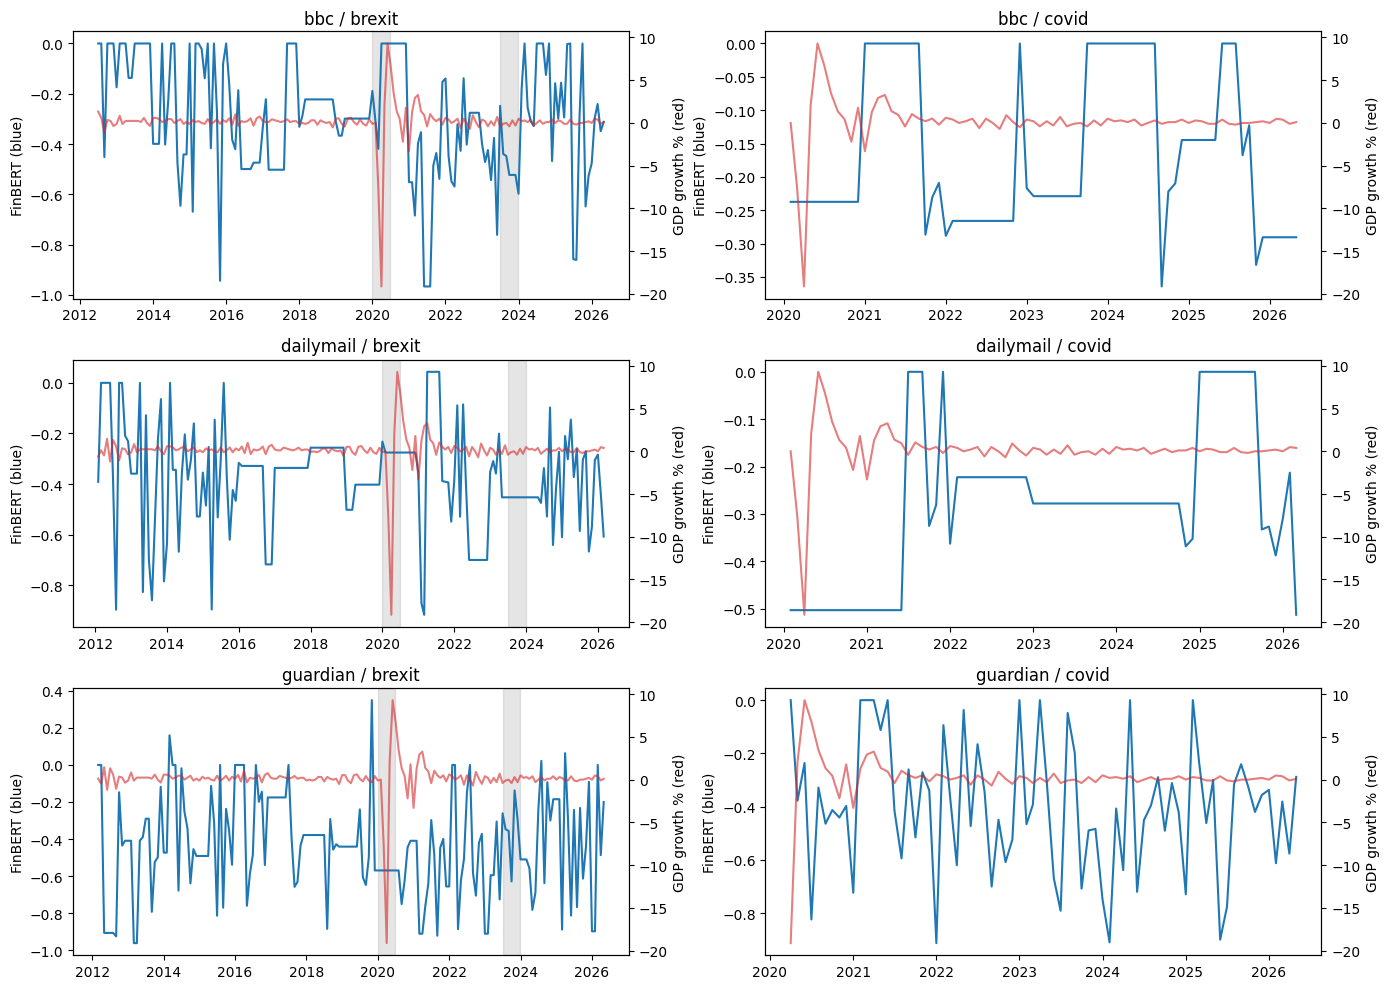

Saved to /content/drive/MyDrive/brexit_covid_datasets/timeseries_plots.png


In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(OUTLETS), len(TOPICS), figsize=(14, 10), sharex=False)
for i, outlet in enumerate(OUTLETS):
    for j, topic in enumerate(TOPICS):
        ax = axes[i, j]
        key = (outlet, topic)
        if key not in datasets or "finbert_score" not in datasets[key].columns:
            ax.set_visible(False)
            continue
        df = datasets[key]
        monthly_sent = df.set_index("publish_date")["finbert_score"].resample(AGG_FREQ).mean()
        merged = pd.DataFrame({"finbert": monthly_sent}).join(econ, how="inner")
        merged = merged.ffill().dropna()
        merged["growth"] = merged["econ_value"].pct_change() * 100
        merged = merged.dropna()
        if merged.empty:
            ax.set_visible(False)
            continue

        ax2 = ax.twinx()
        ax.plot(merged.index, merged["finbert"], color="tab:blue", label="FinBERT sentiment")
        ax2.plot(merged.index, merged["growth"], color="tab:red", alpha=0.6, label="GDP growth %")

        if topic == "brexit":
            for w in RECESSION_WINDOWS:
                ax.axvspan(w["start"], w["end"], color="grey", alpha=0.2)

        ax.set_title(f"{outlet} / {topic}")
        ax.set_ylabel("FinBERT (blue)")
        ax2.set_ylabel("GDP growth % (red)")

plt.tight_layout()
plt.savefig(f"{DATA_DIR}/timeseries_plots.png", dpi=150)
plt.show()
print(f"Saved to {DATA_DIR}/timeseries_plots.png")


/tmp/ipykernel_1129/3905517600.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(sub["model"], rotation=45, ha="right")
/tmp/ipykernel_1129/3905517600.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(sub["model"], rotation=45, ha="right")
/tmp/ipykernel_1129/3905517600.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(sub["model"], rotation=45, ha="right")
/tmp/ipykernel_1129/3905517600.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(sub["model"], rotation=45, ha="right")
/tmp/ipykernel_1129/3905517600.py:13: UserWarning: set_ticklabels() should only be used with a f

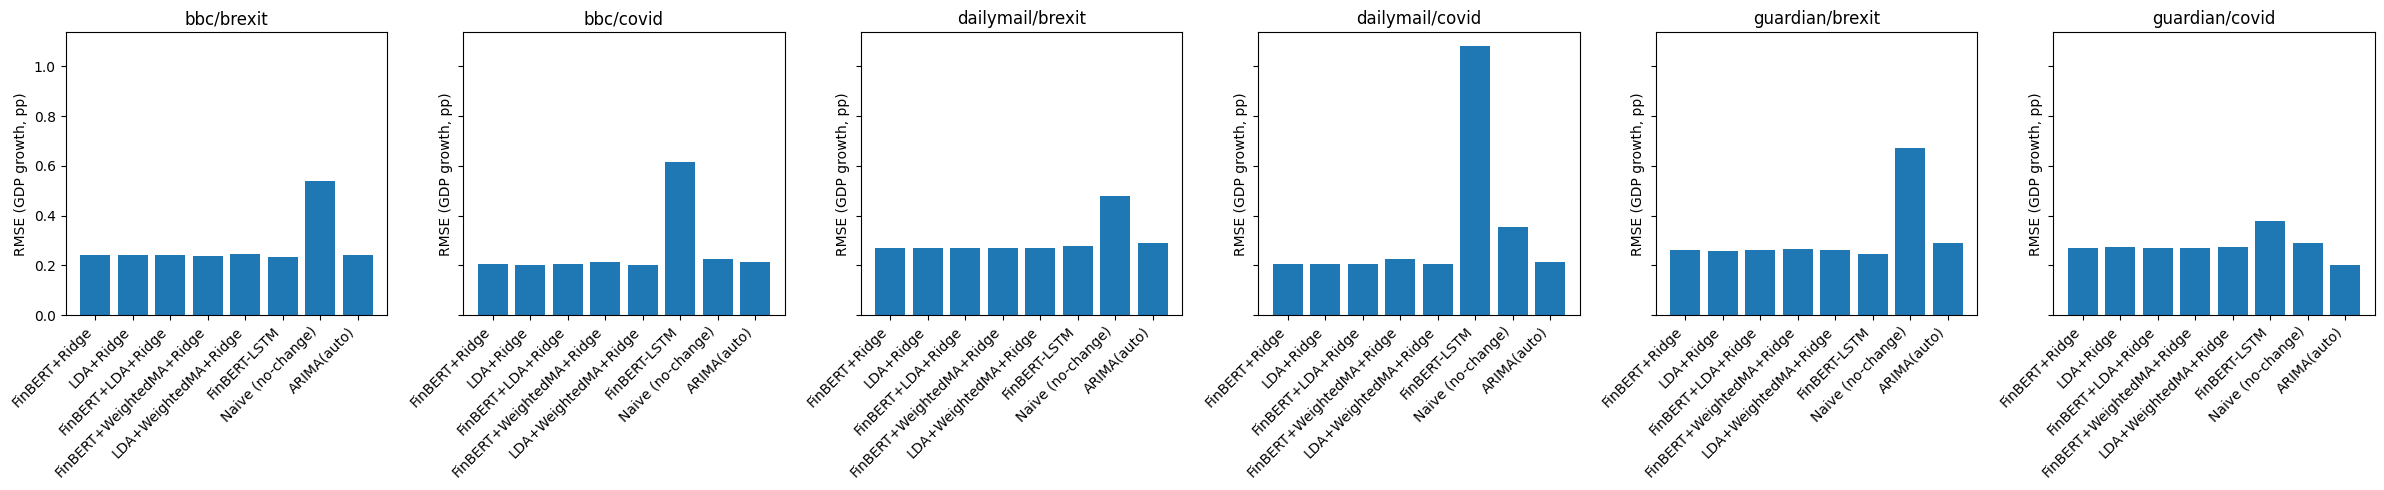

Saved to /content/drive/MyDrive/brexit_covid_datasets/model_comparison_bars.png


In [15]:
import matplotlib.pyplot as plt

dataset_keys = results_df[["outlet", "topic"]].drop_duplicates().values.tolist()
n = len(dataset_keys)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 5), sharey=True)
if n == 1:
    axes = [axes]

for ax, (outlet, topic) in zip(axes, dataset_keys):
    sub = results_df[(results_df["outlet"] == outlet) & (results_df["topic"] == topic)]
    ax.bar(sub["model"], sub["rmse"])
    ax.set_title(f"{outlet}/{topic}")
    ax.set_xticklabels(sub["model"], rotation=45, ha="right")
    ax.set_ylabel("RMSE (GDP growth, pp)")

plt.tight_layout()
plt.savefig(f"{DATA_DIR}/model_comparison_bars.png", dpi=150)
plt.show()
print(f"Saved to {DATA_DIR}/model_comparison_bars.png")


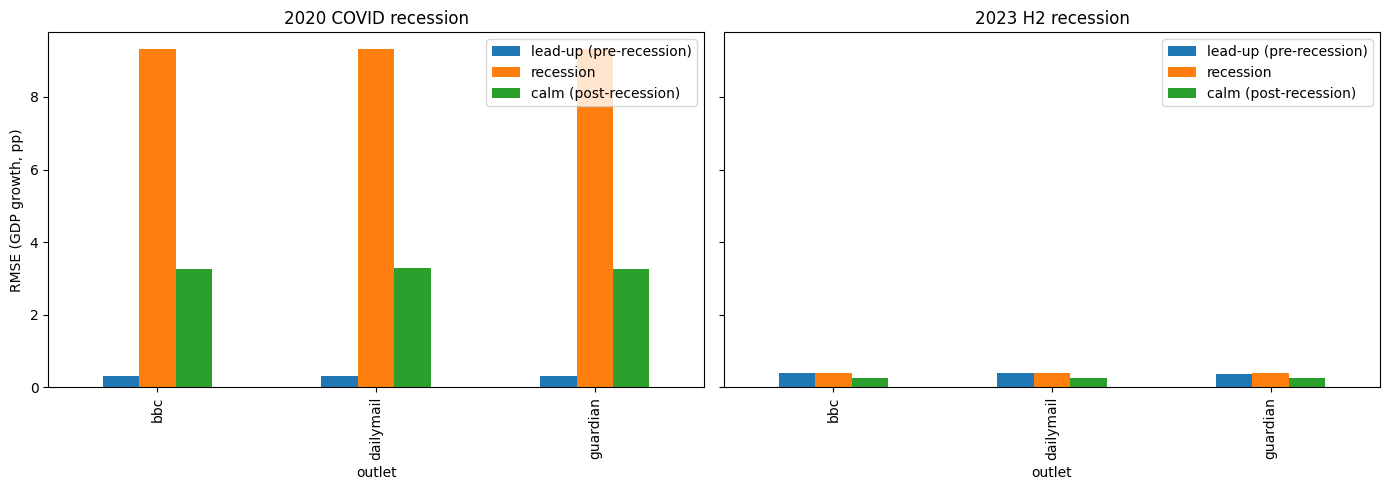

Saved to /content/drive/MyDrive/brexit_covid_datasets/recession_comparison_bars.png


In [16]:
import matplotlib.pyplot as plt

recessions = recession_df["recession"].unique()
period_order = ["lead-up (pre-recession)", "recession", "calm (post-recession)"]

fig, axes = plt.subplots(1, len(recessions), figsize=(7 * len(recessions), 5), sharey=True)
if len(recessions) == 1:
    axes = [axes]

for ax, rec in zip(axes, recessions):
    sub = recession_df[recession_df["recession"] == rec]
    pivot = sub.pivot(index="outlet", columns="period", values="rmse").reindex(columns=period_order)
    pivot.plot(kind="bar", ax=ax)
    ax.set_title(rec)
    ax.set_ylabel("RMSE (GDP growth, pp)")
    ax.legend(title="")

plt.tight_layout()
plt.savefig(f"{DATA_DIR}/recession_comparison_bars.png", dpi=150)
plt.show()
print(f"Saved to {DATA_DIR}/recession_comparison_bars.png")


## Diagnostic: Covid-topic article volume over time



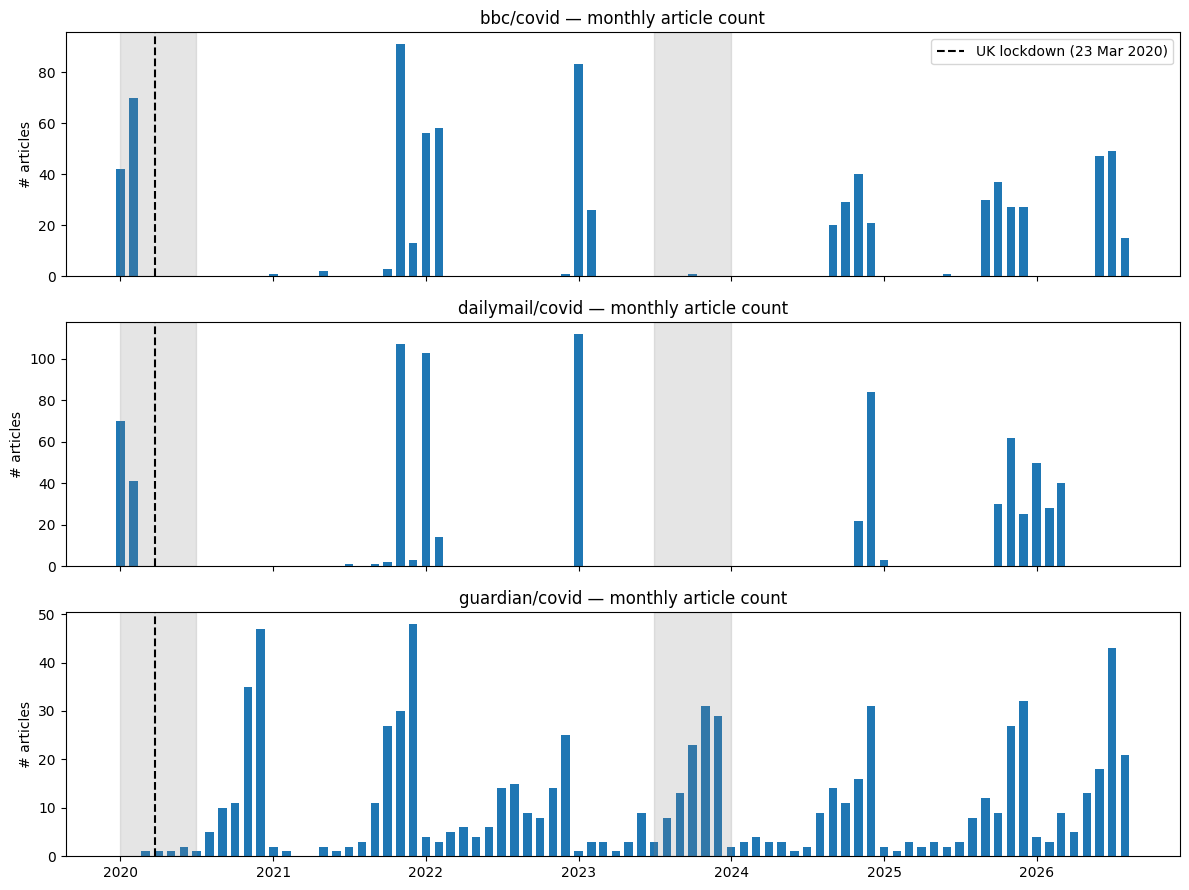

Saved to /content/drive/MyDrive/brexit_covid_datasets/covid_topic_volume_diagnostic.png

=== Covid-topic volume by candidate window ===

--- bbc ---
  Pre-lockdown window (Jan-22 Mar 2020):         112 articles, 3 months
  2020 recession window (23 Mar-Jun 2020):          0 articles, 3 months
  2022 (full year, post-restrictions):            115 articles, 12 months
  Lead-up to 2023 H2 recession (Jan-Jun 2023):    109 articles, 6 months
  2023 H2 recession window (Jul-Dec 2023):          1 articles, 6 months

--- dailymail ---
  Pre-lockdown window (Jan-22 Mar 2020):         111 articles, 3 months
  2020 recession window (23 Mar-Jun 2020):          0 articles, 3 months
  2022 (full year, post-restrictions):            117 articles, 12 months
  Lead-up to 2023 H2 recession (Jan-Jun 2023):    112 articles, 6 months
  2023 H2 recession window (Jul-Dec 2023):          0 articles, 6 months

--- guardian ---
  Pre-lockdown window (Jan-22 Mar 2020):           1 articles, 1 months
  2020 reces

In [17]:
import matplotlib.pyplot as plt

LOCKDOWN_DATE = pd.Timestamp("2020-03-23")  # UK national lockdown announced

fig, axes = plt.subplots(len(OUTLETS), 1, figsize=(12, 3 * len(OUTLETS)), sharex=True)
if len(OUTLETS) == 1:
    axes = [axes]

covid_monthly_counts = {}

for ax, outlet in zip(axes, OUTLETS):
    key = (outlet, "covid")
    if key not in datasets:
        ax.set_visible(False)
        continue
    df = datasets[key]
    monthly_counts = df.set_index("publish_date").resample(AGG_FREQ).size()
    covid_monthly_counts[outlet] = monthly_counts

    ax.bar(monthly_counts.index, monthly_counts.values, width=20, color="tab:blue")
    ax.axvline(LOCKDOWN_DATE, color="black", linestyle="--", label="UK lockdown (23 Mar 2020)")
    for w in RECESSION_WINDOWS:
        ax.axvspan(w["start"], w["end"], color="grey", alpha=0.2)
    ax.set_title(f"{outlet}/covid — monthly article count")
    ax.set_ylabel("# articles")

axes[0].legend(loc="upper right")
plt.tight_layout()
plt.savefig(f"{DATA_DIR}/covid_topic_volume_diagnostic.png", dpi=150)
plt.show()
print(f"Saved to {DATA_DIR}/covid_topic_volume_diagnostic.png")

# ---- Numeric summary: does either candidate window have enough data? ----
print("\n=== Covid-topic volume by candidate window ===\n")
for outlet, monthly in covid_monthly_counts.items():
    pre_lockdown       = monthly[(monthly.index >= "2020-01-01") & (monthly.index < LOCKDOWN_DATE)]
    covid_recession    = monthly[(monthly.index >= "2020-03-23") & (monthly.index <= "2020-06-30")]
    year_2022          = monthly[(monthly.index >= "2022-01-01") & (monthly.index <= "2022-12-31")]
    pre_2023_recession = monthly[(monthly.index >= "2023-01-01") & (monthly.index <  "2023-07-01")]
    in_2023_recession  = monthly[(monthly.index >= "2023-07-01") & (monthly.index <= "2023-12-31")]

    print(f"--- {outlet} ---")
    print(f"  Pre-lockdown window (Jan-22 Mar 2020):        {pre_lockdown.sum():>4} articles, {len(pre_lockdown)} months")
    print(f"  2020 recession window (23 Mar-Jun 2020):       {covid_recession.sum():>4} articles, {len(covid_recession)} months")
    print(f"  2022 (full year, post-restrictions):           {year_2022.sum():>4} articles, {len(year_2022)} months")
    print(f"  Lead-up to 2023 H2 recession (Jan-Jun 2023):   {pre_2023_recession.sum():>4} articles, {len(pre_2023_recession)} months")
    print(f"  2023 H2 recession window (Jul-Dec 2023):       {in_2023_recession.sum():>4} articles, {len(in_2023_recession)} months")
    print()

print("Rule of thumb: if a window averages less than ~5-10 articles/month, treat it as")
print("unusable for a monthly sentiment signal, regardless of the conceptual argument")
print("for including it.")
